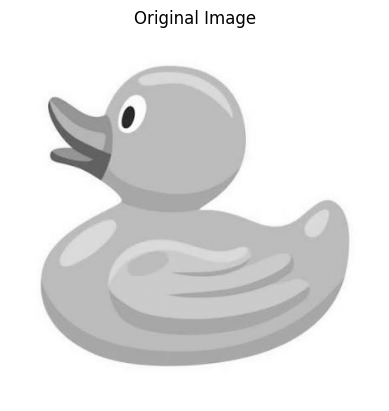

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image


img = Image.open("Duck.JPG").convert("L")
img = np.array(img)

plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")
plt.show()


## Define the convolution kernels

In [ ]:
Gx = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
])

Gy = np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
])

#These are the Sobel filters. One detects intensity changes in one direction, and the other detects changes in the perpendicular direction.

In [3]:
def convolution(image, kernel):
    h, w = image.shape
    kh, kw = kernel.shape

    output = np.zeros((h- kh + 1, w - kw + 1))

    for i in range (h - kh + 1):
        for j in range (w - kw + 1):
            region = image[i:i+kh, j: j+kw]
            output[i, j] = np.sum(region* kernel)

    return output

In [4]:
gx = convolution(img, Gx)
gy = convolution(img, Gy)

edges = np.sqrt(gx**2 + gy**2)

# Normalize the result for display
edges = edges / edges.max() * 255
edges = edges.astype(np.uint8)

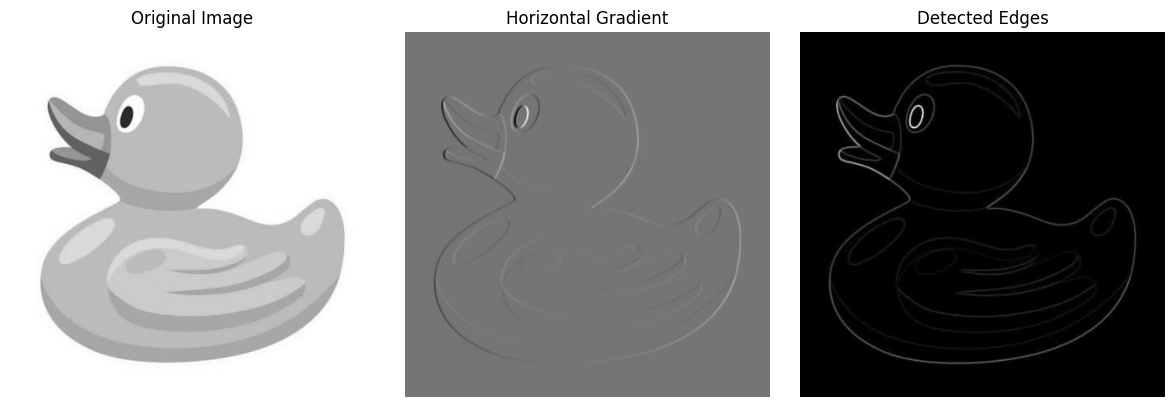

In [5]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gx, cmap="gray")
plt.title("Horizontal Gradient")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(edges, cmap="gray")
plt.title("Detected Edges")
plt.axis("off")

plt.tight_layout()
plt.show()